Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 130, 64)             │          19,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 130, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 32,929 (128.63 KB)

 Trainable params: 32,929 (128.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.6527 - loss: 0.6637 - val_accuracy: 0.6389 - val_loss: 0.6541
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.7389 - loss: 0.5769 - val_accuracy: 0.6759 - val_loss: 0.6685
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.7786 - loss: 0.4977 - val_accuracy: 0.7407 - val_loss: 0.5641
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.8345 - loss: 0.4416 - val_accuracy: 0.8426 - val_loss: 0.3900
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - accuracy: 0.8648 - loss: 0.3670 - val_accuracy: 0.8241 - val_loss: 0.4666
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.8834 - loss: 0.3095 - val_accuracy: 0.8426 - val_loss: 0.3565
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.8904 - loss: 0.2802 - val_accuracy: 0.8241 - val_loss: 0.4719
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.8834 - loss: 0.2944 - val_accuracy: 0

LSTM Model Test Accuracy: 0.9111111164093018


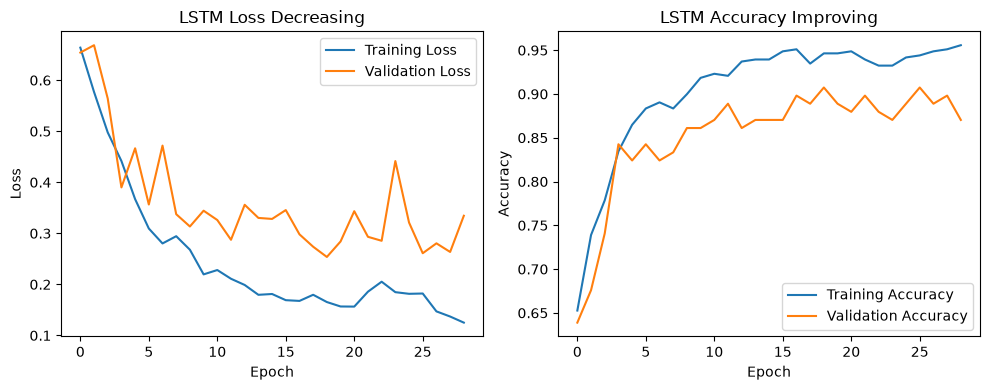

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

X_train = np.load("../data/X_seq_train.npy")
X_test = np.load("../data/X_seq_test.npy")
y_train = np.load("../data/y_train.npy")
y_test = np.load("../data/y_test.npy")

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    layers.LSTM(64, return_sequences=True),   # looks at the sequence, keeps time info
    layers.Dropout(0.3),
    layers.LSTM(32),                          # summarizes the whole sequence
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),      # ACTIVATION: ReLU
    layers.Dense(1, activation="sigmoid")     # ACTIVATION: Sigmoid (final output)
])

model.summary()

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

test_loss, test_acc = model.evaluate(X_test, y_test)
print("LSTM Model Test Accuracy:", test_acc)

model.save("../models/lstm_model.h5")

# Visual proof of learning, same as baseline
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Loss Decreasing')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Accuracy Improving')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout()
plt.savefig("../data/lstm_training_plot.png")
plt.show()